# MF703 BTC project — shared data preparation (processed-v1)

Data lead: Heng Zhang

This notebook turns the raw one-minute BTC/USD bars (`raw-v1`) into the
shared files every model owner uses:

| Output (in `data/processed/processed-v1/`) | Content |
|---|---|
| `btc_1min_clean.parquet` | Cleaned one-minute bars on a complete minute grid |
| `features_15min.parquet` | One row per fifteen-minute forecast time: shared features, `y_true`, `split` |
| `evaluation_index.csv` | Frozen evaluation schedule: `timestamp, y_true, split` |
| `qc_summary.json` | Row counts, exclusions and zero-return baseline scores |

Run from the repository root: `python notebooks/data/prepare_data.py`
(or run all cells of `prepare_data.ipynb`).

In [1]:
import glob
import json
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Locate the repository root whether this is run as a script or a notebook.
ROOT = Path.cwd()
while not (ROOT / "config.json").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("config.json not found; run inside the repository")
    ROOT = ROOT.parent

CONFIG = json.loads((ROOT / "config.json").read_text())
RAW_DIR = ROOT / CONFIG["data"]["raw_dir"]
VERSION = "processed-v1"
OUT_DIR = ROOT / CONFIG["data"]["processed_dir"] / VERSION
FIG_DIR = ROOT / "notebooks" / "data" / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

HORIZON = CONFIG["task"]["horizon_minutes"]            # 15
STEP = CONFIG["task"]["sample_interval_minutes"]       # 15
DEV_START = pd.Timestamp(CONFIG["split"]["development_start"])   # 2017-01-01
TEST_START = pd.Timestamp(CONFIG["split"]["test_start"])         # 2024-01-01
VAL_YEARS = CONFIG["split"]["validation_years"]                  # [2021, 2022, 2023]
WARMUP_START = DEV_START - pd.Timedelta(days=31)   # history kept only to warm up features

## 1. Load the raw data

Either the single file `btcusd_1-min_data.parquet` or the eight parts
`part-000 … part-007` (concatenated in filename order) may be present.

In [2]:
single = ROOT / CONFIG["data"]["raw_path"]
if single.exists():
    raw = pd.read_parquet(single)
else:
    parts = sorted(glob.glob(str(RAW_DIR / CONFIG["data"]["raw_glob"])))
    if not parts:
        raise FileNotFoundError(f"No raw parquet files in {RAW_DIR}")
    raw = pd.concat([pd.read_parquet(p) for p in parts], ignore_index=True)

print(f"raw rows: {len(raw):,}")
raw.head()

raw rows: 7,206,877


,Timestamp,Open,High,Low,Close,Volume
0,1.325412e+09,4.58,4.58,4.58,4.58,0.0
1,1.325412e+09,4.58,4.58,4.58,4.58,0.0
2,1.325412e+09,4.58,4.58,4.58,4.58,0.0
3,1.325412e+09,4.58,4.58,4.58,4.58,0.0
4,1.325412e+09,4.58,4.58,4.58,4.58,0.0


## 2. Quality checks on the raw file

`Timestamp` is Unix **seconds, UTC**, and marks the **start (open) of each
one-minute bar**. A bar stamped `12:14` therefore covers 12:14:00–12:14:59 and
its `Close` only becomes known at `12:15:00`.

In [3]:
PRICE_COLS = ["Open", "High", "Low", "Close"]
raw["Timestamp"] = raw["Timestamp"].round().astype("int64")
raw["bar_open"] = pd.to_datetime(raw["Timestamp"], unit="s")   # naive datetime = UTC

step = raw["Timestamp"].diff().dropna()
gaps = raw.loc[step[step != 60].index, ["bar_open"]].assign(gap_seconds=step[step != 60])
bad_ohlc = (raw["High"] < raw[["Open", "Close"]].max(axis=1)) | (
    raw["Low"] > raw[["Open", "Close"]].min(axis=1)
)

qc = {
    "raw_version": CONFIG["data"]["raw_version"],
    "processed_version": VERSION,
    "raw_rows": int(len(raw)),
    "raw_start_utc": str(raw["bar_open"].iloc[0]),
    "raw_end_utc": str(raw["bar_open"].iloc[-1]),
    "sorted": bool(raw["Timestamp"].is_monotonic_increasing),
    "duplicate_timestamps": int(raw["Timestamp"].duplicated().sum()),
    "off_minute_timestamps": int((raw["Timestamp"] % 60 != 0).sum()),
    "missing_values": int(raw[PRICE_COLS + ["Volume"]].isna().sum().sum()),
    "nonpositive_prices": int((raw[PRICE_COLS] <= 0).any(axis=1).sum()),
    "negative_volume": int((raw["Volume"] < 0).sum()),
    "inconsistent_ohlc": int(bad_ohlc.sum()),
    "zero_volume_rows": int((raw["Volume"] == 0).sum()),
    "gaps": [
        {"resumes_at_utc": str(r.bar_open), "missing_minutes": int(r.gap_seconds // 60 - 1)}
        for r in gaps.itertuples()
    ],
}
for k, v in qc.items():
    print(f"{k:>24}: {v}")

             raw_version: raw-v1
       processed_version: processed-v1
                raw_rows: 7206877
           raw_start_utc: 2012-01-01 10:01:00
             raw_end_utc: 2025-09-14 23:57:00
                  sorted: True
    duplicate_timestamps: 0
   off_minute_timestamps: 0
          missing_values: 0
      nonpositive_prices: 0
         negative_volume: 0
       inconsistent_ohlc: 0
        zero_volume_rows: 1310260
                    gaps: [{'resumes_at_utc': '2025-03-15 19:21:00', 'missing_minutes': 1160}]


**Cleaning rules** (none of them uses future information):

1. Sort by time and drop duplicate timestamps (keep the first) — the raw file has none.
2. Drop rows with missing, non-positive or internally inconsistent prices — the raw file has none.
3. Keep only bars from one month before 2017-01-01 (feature warm-up) onward.
4. Re-index to a complete one-minute grid. Missing minutes stay **NaN** and are
   flagged `is_missing=1`; they are **not** filled.
5. Zero-volume bars are kept: the source repeats the last traded price when no
   trade occurs, which is exactly what a trader would have seen. They are flagged
   `is_zero_volume=1`.
6. Large moves are kept. The biggest post-2017 one-minute moves (2017-03-10 ETF
   rejection, 2019-05-17 Bitstamp flash crash) are real, high-volume events.

In [4]:
clean = raw.sort_values("Timestamp").drop_duplicates("Timestamp", keep="first")
valid = (
    clean[PRICE_COLS + ["Volume"]].notna().all(axis=1)
    & (clean[PRICE_COLS] > 0).all(axis=1)
    & (clean["Volume"] >= 0)
    & ~bad_ohlc.reindex(clean.index, fill_value=False)
)
clean = clean[valid & (clean["bar_open"] >= WARMUP_START)].set_index("bar_open")

full_index = pd.date_range(clean.index[0], clean.index[-1], freq="1min", name="bar_open")
m = clean[PRICE_COLS + ["Volume"]].reindex(full_index)
m["is_missing"] = m["Close"].isna().astype("int8")
m["is_zero_volume"] = (m["Volume"] == 0).astype("int8")
# Time at which the completed bar becomes available to a forecaster.
m.insert(0, "available_time", m.index + pd.Timedelta(minutes=1))

qc["clean_minute_rows"] = int(len(m))
qc["clean_start_utc"] = str(m.index[0])
qc["clean_end_utc"] = str(m.index[-1])
qc["clean_missing_minutes"] = int(m["is_missing"].sum())
qc["clean_zero_volume_rows"] = int(m["is_zero_volume"].sum())
print(f"clean grid: {len(m):,} minutes, {qc['clean_missing_minutes']:,} missing, "
      f"{qc['clean_zero_volume_rows']:,} zero-volume")

m.reset_index().to_parquet(OUT_DIR / "btc_1min_clean.parquet", index=False)

clean grid: 4,622,398 minutes, 1,160 missing, 163,423 zero-volume


## 3. Target

From here on everything is indexed by **availability time** `t`
(= bar open + 1 minute). `P_t` is the `Close` of the last bar completed at `t`.

$$y_t = \ln\left(\frac{P_{t+15\text{min}}}{P_t}\right)$$

Because the grid is complete, `shift(-15)` is a true fifteen-minute step in
elapsed time; if either end falls in a gap, the target is NaN and the sample
is excluded. Nothing is ever shifted across a gap.

In [5]:
a = m.set_index("available_time")          # index = time the bar is known
log_p = np.log(a["Close"])

feat = pd.DataFrame(index=a.index)
feat["price_t"] = a["Close"]
feat["price_t_plus_15"] = a["Close"].shift(-HORIZON)
feat["y_true"] = log_p.shift(-HORIZON) - log_p

## 4. Shared features

Every feature at time `t` uses bars completed at or before `t` only. Rolling
windows require a full window (`min_periods = window`), so a window touching
a gap or the start of the data yields NaN. No scaling is applied here: model
owners fit any scaler on their own training fold.

In [6]:
RET_WINDOWS = [1, 5, 15, 30, 60, 240, 1440]
ROLL_WINDOWS = [15, 60, 240, 1440]
N_AR_LAGS = 12

# Past log returns over k minutes: ln(P_t / P_{t-k})
for k in RET_WINDOWS:
    feat[f"ret_{k}"] = log_p - log_p.shift(k)

# Lagged non-overlapping fifteen-minute returns (convenient for AR models):
# ret_15_lag{j} = ln(P_{t-15j} / P_{t-15(j+1)})
for j in range(1, N_AR_LAGS + 1):
    feat[f"ret_15_lag{j}"] = feat["ret_15"].shift(HORIZON * j)

r1 = feat["ret_1"]
for w in ROLL_WINDOWS:
    # Gap between price and its moving average: ln(P_t / mean(P_{t-w+1..t}))
    feat[f"ma_gap_{w}"] = log_p - np.log(a["Close"].rolling(w, min_periods=w).mean())
    # Realised volatility: std of one-minute log returns over the window
    feat[f"vol_{w}"] = r1.rolling(w, min_periods=w).std()

# Candle built from the last fifteen completed one-minute bars
hi = a["High"].rolling(HORIZON, min_periods=HORIZON).max()
lo = a["Low"].rolling(HORIZON, min_periods=HORIZON).min()
op = a["Open"].shift(HORIZON - 1)
feat["range_15"] = np.log(hi / lo)
feat["body_15"] = np.log(a["Close"] / op)
feat["upper_shadow_15"] = np.log(hi / np.maximum(op, a["Close"]))
feat["lower_shadow_15"] = np.log(np.minimum(op, a["Close"]) / lo)
hi60 = a["High"].rolling(60, min_periods=60).max()
lo60 = a["Low"].rolling(60, min_periods=60).min()
feat["range_60"] = np.log(hi60 / lo60)

# Volume (BTC traded)
v15 = a["Volume"].rolling(15, min_periods=15).sum()
feat["log_volume_15"] = np.log1p(v15)
feat["volume_chg_15"] = np.log1p(v15) - np.log1p(v15.shift(15))
feat["volume_rel_240"] = np.log1p(v15) - np.log1p(a["Volume"].rolling(240, min_periods=240).sum() / 16)
feat["volume_rel_1440"] = np.log1p(v15) - np.log1p(a["Volume"].rolling(1440, min_periods=1440).sum() / 96)
feat["zero_volume_frac_15"] = (a["Volume"] == 0).astype(float).where(a["Volume"].notna()).rolling(15, min_periods=15).mean()

# Calendar (UTC)
feat["hour"] = feat.index.hour.astype("int8")
feat["day_of_week"] = feat.index.dayofweek.astype("int8")   # Monday = 0

META_COLS = ["price_t", "price_t_plus_15", "y_true"]
FEATURE_COLS = [c for c in feat.columns if c not in META_COLS]
print(f"{len(FEATURE_COLS)} shared features")

39 shared features


## 5. Fifteen-minute forecast grid, splits and exclusions

Forecast times are UTC minutes 00, 15, 30 and 45 from 2017-01-01 00:00.
A forecast time is kept only if **both** the target and every shared feature
are available, so all models can cover every required row.

| split label | Role |
|---|---|
| `train` | 2017–2020: never an evaluation period |
| `val2021`, `val2022`, `val2023` | Validation years (training data for later folds) |
| `test` | 2024-01-01 through the last valid target |

In [7]:
grid = feat[(feat.index.minute % STEP == 0) & (feat.index.second == 0) & (feat.index >= DEV_START)].copy()

no_target = grid["y_true"].isna()
no_features = grid[FEATURE_COLS].isna().any(axis=1)
grid["exclusion"] = np.select(
    [no_target & no_features, no_target, no_features],
    ["target_and_features_unavailable", "target_unavailable", "features_unavailable"],
    default="",
)


def label_split(ts: pd.DatetimeIndex) -> np.ndarray:
    out = np.full(len(ts), "train", dtype=object)
    for y in VAL_YEARS:
        out[ts.year == y] = f"val{y}"
    out[ts >= TEST_START] = "test"
    return out


grid["split"] = label_split(grid.index)
excluded = grid[grid["exclusion"] != ""]
data = grid[grid["exclusion"] == ""].drop(columns="exclusion")
data.index.name = "timestamp"

print("excluded forecast times:")
print(excluded.groupby(["split", "exclusion"]).size().to_string() if len(excluded) else "  none")
if len(excluded):
    print(f"  from {excluded.index.min()} to {excluded.index.max()}")

excluded forecast times:
split  exclusion                      
test   features_unavailable               96
       target_and_features_unavailable    77
       target_unavailable                  2
  from 2025-03-15 00:00:00 to 2025-09-14 23:45:00


## 6. Leakage and consistency checks

In [8]:
# (a) Recompute the target for a random sample straight from the raw bars.
raw_close = raw.set_index("bar_open")["Close"]
sample = data.sample(2000, random_state=CONFIG["random_seed"])
p0 = raw_close.reindex(sample.index - pd.Timedelta(minutes=1)).to_numpy()
p1 = raw_close.reindex(sample.index + pd.Timedelta(minutes=HORIZON - 1)).to_numpy()
assert np.allclose(np.log(p1 / p0), sample["y_true"].to_numpy(), atol=1e-12), "target mismatch"

# (b) Features must not change if the future is removed.
cut = pd.Timestamp("2023-06-01 00:00")
expected = np.log(raw_close[cut - pd.Timedelta(minutes=1)] / raw_close[cut - pd.Timedelta(minutes=16)])
assert np.isclose(data.loc[cut, "ret_15"], expected, atol=1e-12), "feature uses wrong bars"

# (c) Structure
assert data.index.is_unique and data.index.is_monotonic_increasing
assert not data.isna().any().any()
assert set(data["split"]) == {"train", "test"} | {f"val{y}" for y in VAL_YEARS}
# The last training target of each fold ends no later than the evaluation start.
for y in VAL_YEARS + [TEST_START.year]:
    start = pd.Timestamp(f"{y}-01-01")
    assert data.index[data.index < start].max() + pd.Timedelta(minutes=HORIZON) <= start

# (d) No feature should be suspiciously correlated with the target.
corr = data[FEATURE_COLS].corrwith(data["y_true"]).abs().sort_values(ascending=False)
assert corr.iloc[0] < 0.2, "a feature is implausibly predictive: check for leakage"
print("all checks passed; largest |corr(feature, y_true)|:")
print(corr.head(5).round(4).to_string())

all checks passed; largest |corr(feature, y_true)|:
ret_1              0.0439
ret_5              0.0357
upper_shadow_15    0.0355
ma_gap_15          0.0332
ma_gap_240         0.0299


## 7. Save the shared files and summarise

In [9]:
data.reset_index().to_parquet(OUT_DIR / "features_15min.parquet", index=False)

eval_index = data.loc[data["split"] != "train", ["y_true", "split"]].reset_index()
eval_index["timestamp"] = eval_index["timestamp"].dt.strftime("%Y-%m-%d %H:%M")
eval_index.to_csv(OUT_DIR / "evaluation_index.csv", index=False, float_format="%.12g")
# Location expected by config.json
eval_index.to_csv(ROOT / CONFIG["data"]["evaluation_index_path"], index=False, float_format="%.12g")

summary = (
    data.reset_index()
    .groupby("split", sort=False)
    .agg(
        rows=("y_true", "size"),
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        mean_y=("y_true", "mean"),
        std_y=("y_true", "std"),
        # A zero-return forecast has error y_true, so these are the baseline scores.
        baseline_rmse=("y_true", lambda s: float(np.sqrt(np.mean(s**2)))),
        baseline_mae=("y_true", lambda s: float(np.mean(np.abs(s)))),
    )
)
summary["excluded"] = excluded.groupby("split").size().reindex(summary.index, fill_value=0)
print(summary.to_string())

qc["forecast_grid_rows"] = int(len(grid))
qc["kept_rows"] = int(len(data))
qc["excluded_rows"] = {
    f"{s}/{e}": int(n) for (s, e), n in excluded.groupby(["split", "exclusion"]).size().items()
}
qc["feature_columns"] = FEATURE_COLS
qc["splits"] = json.loads(summary.assign(start=summary["start"].astype(str), end=summary["end"].astype(str)).to_json(orient="index"))
(OUT_DIR / "qc_summary.json").write_text(json.dumps(qc, indent=2))

           rows      start                 end    mean_y     std_y  baseline_rmse  baseline_mae  excluded
split                                                                                                    
train    140256 2017-01-01 2020-12-31 23:45:00  0.000024  0.004760       0.004760      0.002712         0
val2021   35040 2021-01-01 2021-12-31 23:45:00  0.000014  0.004993       0.004993      0.003218         0
val2022   35040 2022-01-01 2022-12-31 23:45:00 -0.000030  0.003434       0.003434      0.002117         0
val2023   35040 2023-01-01 2023-12-31 23:45:00  0.000027  0.002237       0.002237      0.001340         0
test      59633 2024-01-01 2025-09-14 23:30:00  0.000017  0.002650       0.002650      0.001726       175


2919

## 8. Figures for the report

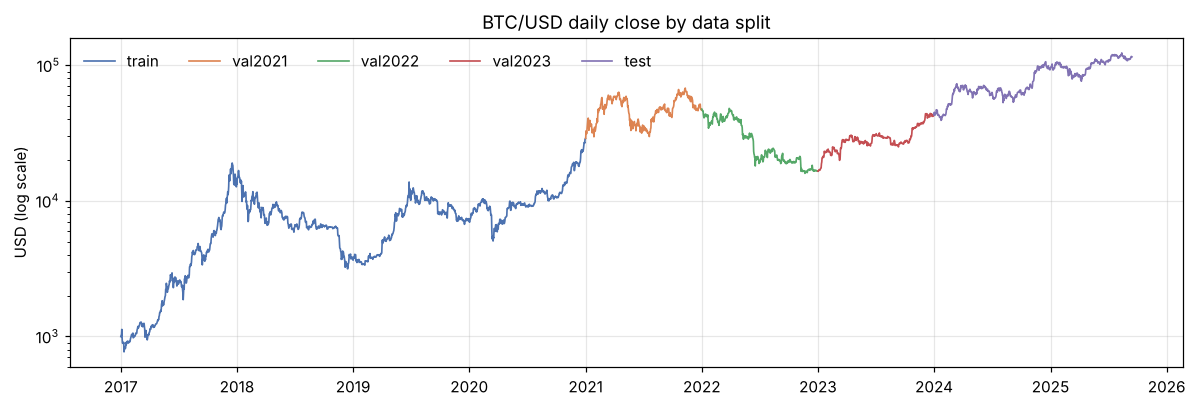

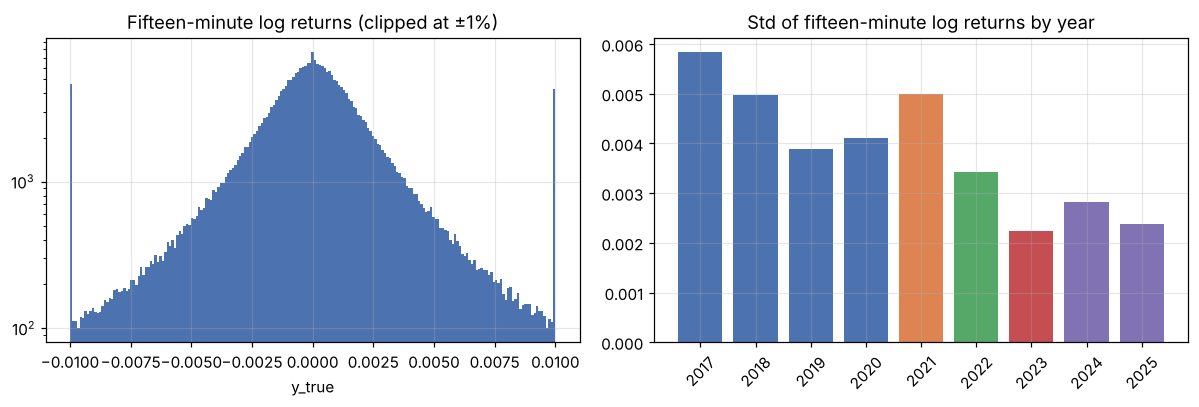

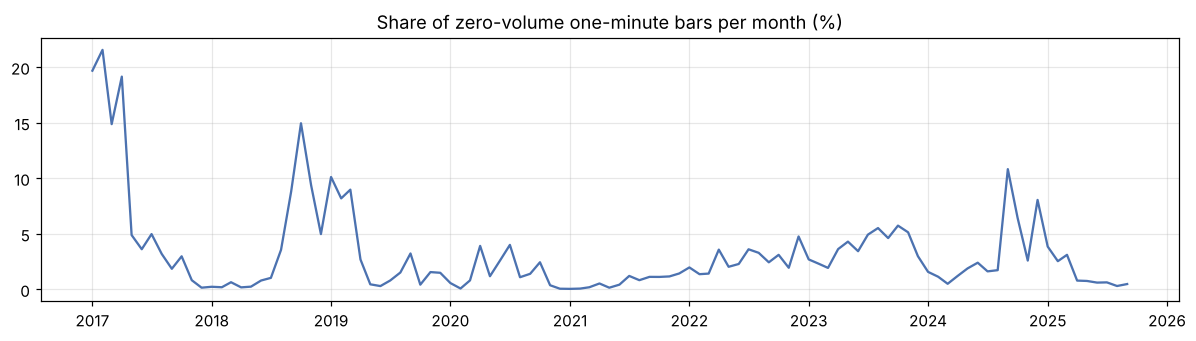

done → /home/user/MF703-Project-Ebaybarebay-English/data/processed/processed-v1


In [10]:
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
colors = {"train": "#4c72b0", "val2021": "#dd8452", "val2022": "#55a868", "val2023": "#c44e52", "test": "#8172b3"}

fig, ax = plt.subplots(figsize=(11, 3.8))
daily = data["price_t"].resample("1D").last()
for s, c in colors.items():
    d = daily[label_split(daily.index) == s]
    ax.plot(d.index, d.values, color=c, label=s, lw=1.1)
ax.set_yscale("log")
ax.set_title("BTC/USD daily close by data split")
ax.set_ylabel("USD (log scale)")
ax.legend(ncol=5, frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "price_by_split.png")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
y = data["y_true"]
axes[0].hist(y.clip(-0.01, 0.01), bins=201, color="#4c72b0")
axes[0].set_yscale("log")
axes[0].set_title("Fifteen-minute log returns (clipped at ±1%)")
axes[0].set_xlabel("y_true")
yearly = y.groupby(y.index.year).std()
axes[1].bar(yearly.index.astype(str), yearly.values, color=[colors[s] for s in label_split(pd.to_datetime(yearly.index.astype(str)))])
axes[1].set_title("Std of fifteen-minute log returns by year")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(FIG_DIR / "target_distribution.png")

fig, ax = plt.subplots(figsize=(11, 3.2))
zv = m.loc[m.index >= DEV_START, "is_zero_volume"].resample("1MS").mean() * 100
ax.plot(zv.index, zv.values, color="#4c72b0")
ax.set_title("Share of zero-volume one-minute bars per month (%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "zero_volume_share.png")

if matplotlib.get_backend().lower() != "agg":
    plt.show()
print(f"done → {OUT_DIR}")